# Simulated Data

In [2]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [3]:
file_path = '/hpc/group/hickeylab/fl135/pkl_data/DLPFC_151673_overlap=80__pseudocount_0_spotIndex.h5'

ad_ = sc.read_h5ad(file_path)


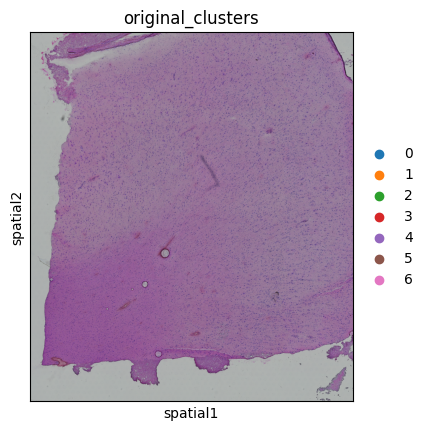

In [4]:
sc.pl.spatial(ad_, color='original_clusters', spot_size=1.5)

In [5]:
file_path = '/hpc/group/hickeylab/fl135/pkl_data/DLPFC_151673_overlap=100__pseudocount_0_spotIndex.h5'

ad_target = sc.read_h5ad(file_path)


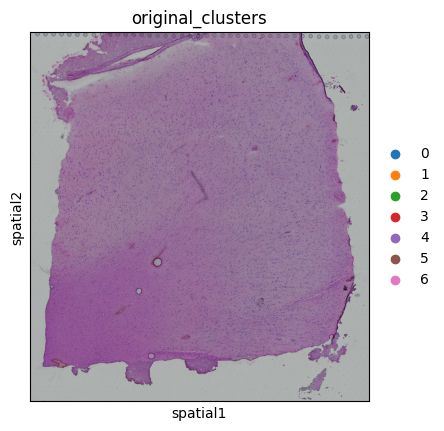

In [6]:
sc.pl.spatial(ad_target, color='original_clusters', spot_size=1.5)

0 of 3596
3595 of 3596


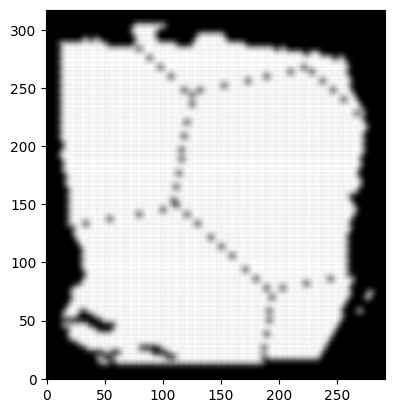

In [7]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 2894
2893 of 2894


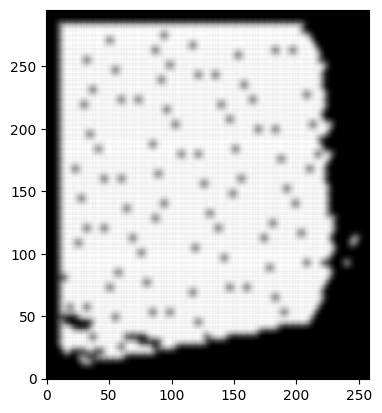

In [8]:
spatial_coords = ad_.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

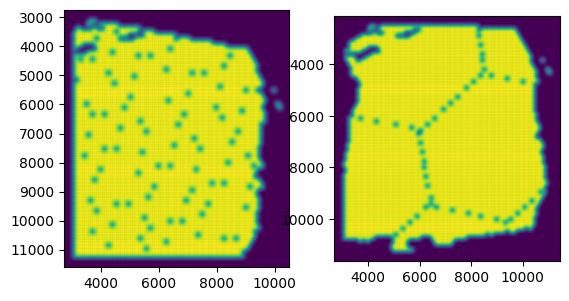

In [9]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
# ax[0].invert_yaxis()
# ax[1].invert_yaxis()

In [16]:
np.savez('./simData-20241219T155123Z-001/DLPFC_151673_overlap=80__pseudocount_0_spotIndex', x=XI,y=YI,I=I)
np.savez('./simData-20241219T155123Z-001/DLPFC_151673_overlap=100__pseudocount_0_spotIndex', x=XJ,y=YJ,I=J)

In [11]:
# read from file
pointsIlist = np.load('./simData-20241219T155123Z-001/npy_data/DLPFC_151673_overlap=80__pseudocount_0_spotIndex_curves.npy', allow_pickle=True).tolist()
print(pointsIlist)
pointsJlist = np.load('./simData-20241219T155123Z-001/npy_data/DLPFC_151673_overlap=100__pseudocount_0_spotIndex_curves.npy', allow_pickle=True).tolist()
print(pointsJlist)

{'0': [(3682.056168831169, 3148.530196879965)], '1': [(10096.991233766235, 6055.673054022822)]}
{'0': [(4146.979220779221, 2556.712853779436)], '1': [(10987.076623376623, 4286.095970662553)]}


In [10]:
pointsIlist = {'0': [(3682.056168831169, 3148.530196879965)], '1': [(10096.991233766235, 6055.673054022822)]}
pointsJlist = {'0': [(4146.979220779221, 2556.712853779436)], '1': [(10987.076623376623, 4286.095970662553)]}

In [11]:
# convert to array
pointsI = []
pointsJ = []

# Jean's note: a bit odd to me that the points are stored as y,x
## instead of x,y but all downstream code uses this orientation
for i in pointsIlist.keys():
    pointsI.append([pointsIlist[i][0][1], pointsIlist[i][0][0]])
for i in pointsJlist.keys():
    pointsJ.append([pointsJlist[i][0][1], pointsJlist[i][0][0]])

pointsI = np.array(pointsI)
pointsJ = np.array(pointsJ)

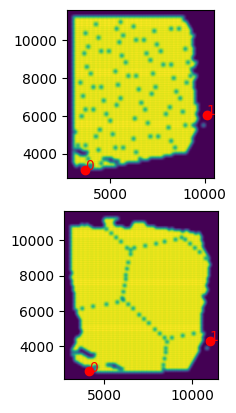

In [12]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(2,1)
ax[0].imshow((I.transpose(1,2,0).squeeze()), extent=extentI) # just want 201x276 matrix
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ) # just want 201x276 matrix
# with points
ax[0].scatter(pointsI[:,1], pointsI[:,0], c='red')
ax[1].scatter(pointsJ[:,1], pointsJ[:,0], c='red')
for i in range(pointsI.shape[0]):
    ax[0].text(pointsI[i,1],pointsI[i,0],f'{i}', c='red')
    ax[1].text(pointsJ[i,1],pointsJ[i,0],f'{i}', c='red')
ax[0].invert_yaxis()
ax[1].invert_yaxis()

In [13]:
# set device for building tensors
if torch.cuda.is_available():
    torch.set_default_device('cuda:0')
else:
    torch.set_default_device('cpu')


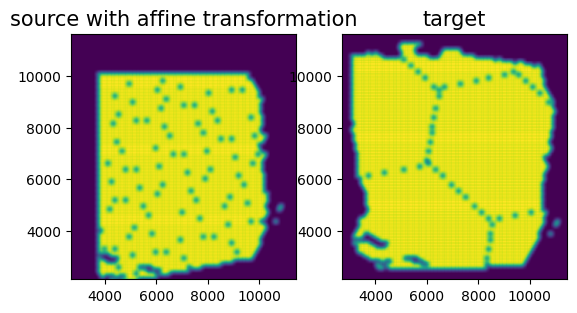

In [14]:
# compute initial affine transformation from points
L,T = STalign.L_T_from_points(pointsI, pointsJ)
A = STalign.to_A(torch.tensor(L),torch.tensor(T))

# compute initial affine transformation from points
AI = STalign.transform_image_source_with_A(A, [YI,XI], I, [YJ,XJ])

#switch tensor from cuda to cpu for plotting with numpy
if AI.is_cuda:
    AI = AI.cpu()

fig,ax = plt.subplots(1,2)
ax[0].imshow((AI.permute(1,2,0).squeeze()), extent=extentJ)
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ)

ax[0].set_title('source with affine transformation', fontsize=15)
ax[1].set_title('target', fontsize=15)

ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 15min 52s, sys: 21.5 s, total: 16min 13s
Wall time: 14min 19s


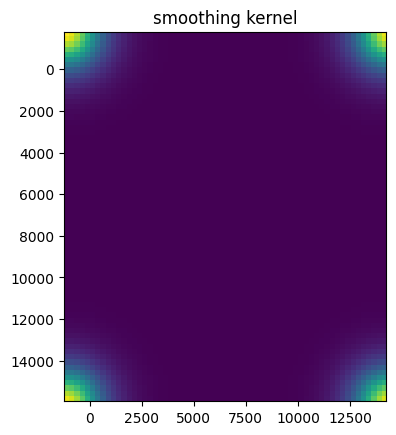

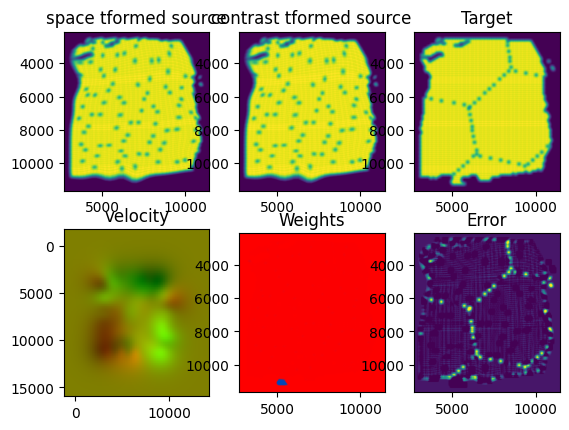

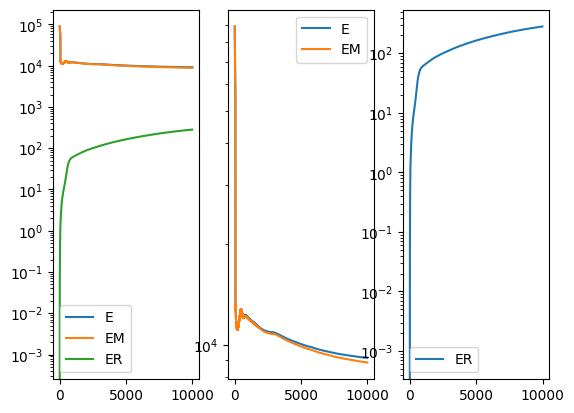

In [15]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            'niter': 10000,
            'device':device,
            'epV': 50,
            'sigmaA': 0.01, #standard deviation of artifact intensities
            'sigmaB': 0.01, #standard deviation of background intensities
            'sigmaM': 0.01, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [17]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [18]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

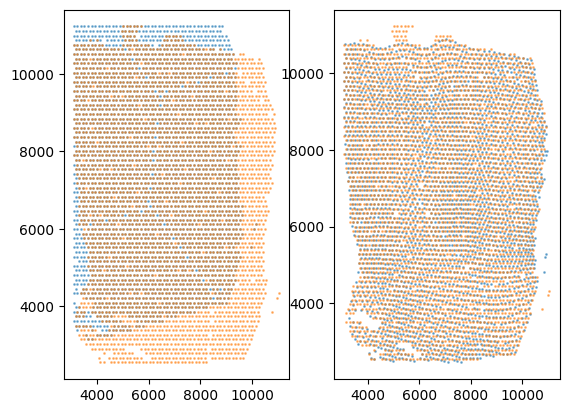

In [19]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [23]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [24]:
# Save as .pkl
alignment_df.to_pickle("100_80_AlignmentPi.pkl")

## LAA

In [25]:
# LAA
#calculate laywise bar, result needs to be devided by total number to calculate the accuracy rate
def cal_layer_based_alignment_result(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    cnt1 = 0
    cnt2 = 0
    cnt3 = 0
    cnt4 = 0
    cnt5 = 0
    cnt6 = 0
    for i, elem in enumerate(alignment):
        if np.max(elem) - np.min(elem) != 0: # paste2 might have spots that are not aligned to any other spots. paste might have negative alignment
            if labels[i] == '-1' or labels[elem.argmax() + alignment.shape[0]] == '-1':
                continue
            if l_dict[labels[i]] == l_dict[labels[elem.argmax() + alignment.shape[0]]]:
                cnt0 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 1:
                cnt1 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 2:
                cnt2 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 3:
                cnt3 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 4:
                cnt4 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 5:
                cnt5 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 6:
                cnt6 += 1
    res.extend([cnt0, cnt1, cnt2, cnt3, cnt4, cnt5, cnt6])
    return res

In [26]:
res = cal_layer_based_alignment_result(alignment, ad_, ad_target)
res

[653, 750, 759, 755, 235, 260, 184]

In [29]:
divisor = alignment.shape[0]
LAA_result = [num / divisor for num in res]
print(LAA_result)

[0.18159065628476084, 0.20856507230255839, 0.2110678531701891, 0.20995550611790878, 0.06535038932146829, 0.07230255839822025, 0.05116796440489433]


In [ ]:
alignment.shape

(3596, 2894)

## ARI

In [30]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [31]:
ari = compute_alignment_ari(ad_target, ad_, alignment)
ari

0.5651082332904208

## Degree

In [43]:
def get_rotation_angle(R):
    # Extract the sine and cosine from the matrix
    cos_theta = R[0, 0]
    sin_theta = R[1, 0]

    # Compute the angle in radians
    theta = np.arctan2(sin_theta, cos_theta)

    # Convert the angle to degrees (optional)
    theta_deg = np.degrees(theta)

    return theta, theta_deg

In [44]:
# https://github.com/raphael-group/paste/blob/main/src/paste/visualization.py
X = np.array([x_target, y_target]).T
print(X.shape)
Y = np.array([x, y]).T
print(Y.shape)
print(alignment.shape)
tX = alignment.sum(axis=1).dot(X)
tY = alignment.sum(axis=0).dot(Y)
X = X - tX
Y = Y - tY
H = Y.T.dot(alignment.T.dot(X))
U, S, Vt = np.linalg.svd(H)
R = Vt.T.dot(U.T)

theta, theta_deg = get_rotation_angle(R)
theta_deg

(3596, 2)
(2894, 2)
(3596, 2894)


-4.529130972114568

## 3D

In [32]:
unique_clusters = ad_.obs['original_clusters']
for jjj in range(1, 2):
    unique_clusters = sorted(np.unique(
        np.concatenate([
            unique_clusters,
            ad_.obs['original_clusters']
        ])
    ))

In [33]:
cmap = []
if len(unique_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=40
    for e in plt.get_cmap('tab20').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
    for e in plt.get_cmap('tab20b').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))

# Create the dictionary with the combined clusters
c_dict = dict(zip(unique_clusters, cmap))

In [34]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

In [35]:
df = pd.read_csv("0.csv")
df

,index,original_clusters,X,Y,Z,slice,celltype_colors
0,AAACAAGTATCTCCCA-1,3,9791.000000,8468.000000,0,0,#d62728
1,AAACAATCTACTAGCA-1,1,5769.000000,2807.000000,0,0,#ff7f0e
2,AAACACCAATAACTGC-1,0,4068.000000,9505.000000,0,0,#1f77b4
3,AAACAGAGCGACTCCT-1,3,9271.000000,4151.000000,0,0,#d62728
4,AAACAGCTTTCAGAAG-1,5,3393.000000,7583.000000,0,0,#8c564b
...,...,...,...,...,...,...,...
7202,TTGTTGTGTGTCAAGA-1,5,8072.137055,6222.676650,1,100,#8c564b
7203,TTGTTTCACATCCAGG-1,0,5646.256071,9345.060746,1,100,#1f77b4
7204,TTGTTTCATTAGTCTA-1,0,4811.014031,9607.076747,1,100,#1f77b4
7205,TTGTTTCCATACAACT-1,6,4608.111472,7816.411188,1,100,#e377c2


In [39]:
dfs = ad_.obs['original_clusters']
df1 = dfs.reset_index()
# df0.head()

df3 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results = pd.concat([df1, df3], axis=1)
results['Z'] = 2
results['slice'] = 80
results['celltype_colors'] = results['original_clusters'].replace(c_dict)
results

,index,original_clusters,X,Y,Z,slice,celltype_colors
0,AAACAAGTATCTCCCA-1,3,9289.882294,9321.188629,2,80,#d62728
1,AAACAATCTACTAGCA-1,1,5758.963327,2866.217386,2,80,#ff7f0e
2,ACAATGAATACGGAGA-1,0,3097.948263,9568.172414,2,80,#1f77b4
3,AAACAGAGCGACTCCT-1,3,9309.060078,4965.740207,2,80,#d62728
4,AGCCCATACATGTAAG-1,6,3154.573081,7659.810886,2,80,#e377c2
...,...,...,...,...,...,...,...
2889,TTGTTCAGTGTGCTAC-1,5,6925.262178,5881.994974,2,80,#8c564b
2890,TTGTTGTGTGTCAAGA-1,5,7694.888983,6934.646073,2,80,#8c564b
2891,TTGTTTCACATCCAGG-1,0,4079.711856,9695.968736,2,80,#1f77b4
2892,TTGTTTCCATACAACT-1,6,3196.551669,8017.760542,2,80,#e377c2


In [46]:
df3.to_csv("_overlap=80_align.csv", index=False)

In [40]:
result = pd.concat([df, results], axis=0)
result

,index,original_clusters,X,Y,Z,slice,celltype_colors
0,AAACAAGTATCTCCCA-1,3,9791.000000,8468.000000,0,0,#d62728
1,AAACAATCTACTAGCA-1,1,5769.000000,2807.000000,0,0,#ff7f0e
2,AAACACCAATAACTGC-1,0,4068.000000,9505.000000,0,0,#1f77b4
3,AAACAGAGCGACTCCT-1,3,9271.000000,4151.000000,0,0,#d62728
4,AAACAGCTTTCAGAAG-1,5,3393.000000,7583.000000,0,0,#8c564b
...,...,...,...,...,...,...,...
2889,TTGTTCAGTGTGCTAC-1,5,6925.262178,5881.994974,2,80,#8c564b
2890,TTGTTGTGTGTCAAGA-1,5,7694.888983,6934.646073,2,80,#8c564b
2891,TTGTTTCACATCCAGG-1,0,4079.711856,9695.968736,2,80,#1f77b4
2892,TTGTTTCCATACAACT-1,6,3196.551669,8017.760542,2,80,#e377c2


In [42]:
result.to_csv("1.csv", index=False)